# 06 — Risk Metrics: VaR and CVaR

**Goal:** compute and compare historical, parametric, and Monte Carlo VaR,
plus CVaR, across confidence levels — and show where the methods agree and
disagree.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'MSFT' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['AAPL', 'MSFT']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['BND', 'GLD', 'SPY']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.portfolio.analytics import portfolio_returns, performance_report
from src.risk.var import historical_var, parametric_var
from src.risk.cvar import historical_cvar

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
port_returns = portfolio_returns(returns_panel, weights)

report = performance_report(port_returns)
pd.Series(report).round(4)

cumulative_return        1.0674
annualized_return        0.0957
annualized_volatility    0.1142
sharpe_ratio             0.6628
sortino_ratio            1.1058
max_drawdown            -0.1703
calmar_ratio             0.5618
historical_var           0.0111
parametric_var           0.0114
cvar                     0.0143
dtype: float64

In [3]:
confidence_levels = [0.90, 0.95, 0.975, 0.99]
rows = []
for cl in confidence_levels:
    rows.append({
        "confidence_level": cl,
        "historical_var": historical_var(port_returns, cl),
        "parametric_var": parametric_var(port_returns, cl),
        "cvar": historical_cvar(port_returns, cl),
    })
var_table = pd.DataFrame(rows).set_index("confidence_level")
(var_table * 100).round(2)

,historical_var,parametric_var,cvar
confidence_level,,,
0.900,0.89,0.88,1.21
0.950,1.11,1.14,1.43
0.975,1.35,1.37,1.66
0.990,1.65,1.63,1.93


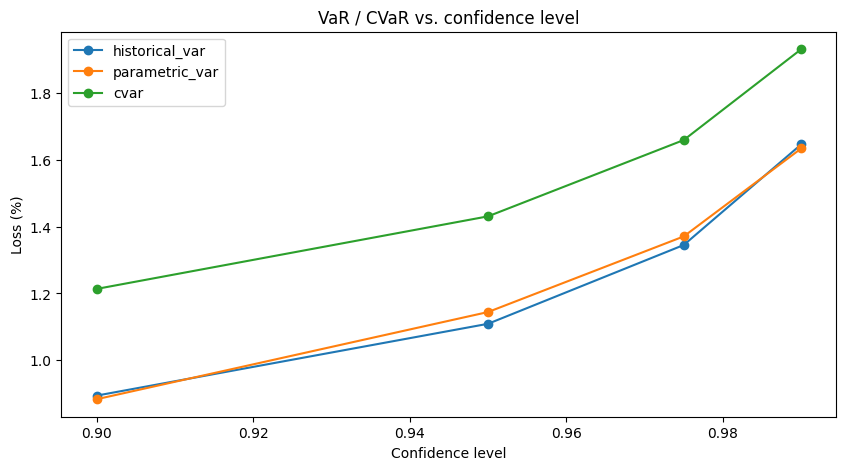

In [4]:
(var_table * 100).plot(marker="o", title="VaR / CVaR vs. confidence level")
plt.ylabel("Loss (%)")
plt.xlabel("Confidence level")
plt.show()

**Note:** CVaR is always ≥ VaR at the same confidence level — it averages over the tail beyond the VaR threshold, so it can never be smaller. Parametric (Gaussian) VaR tends to sit close to historical VaR when returns are roughly Normal, and can understate risk when the empirical distribution has fatter tails (see notebook 03's kurtosis figures).

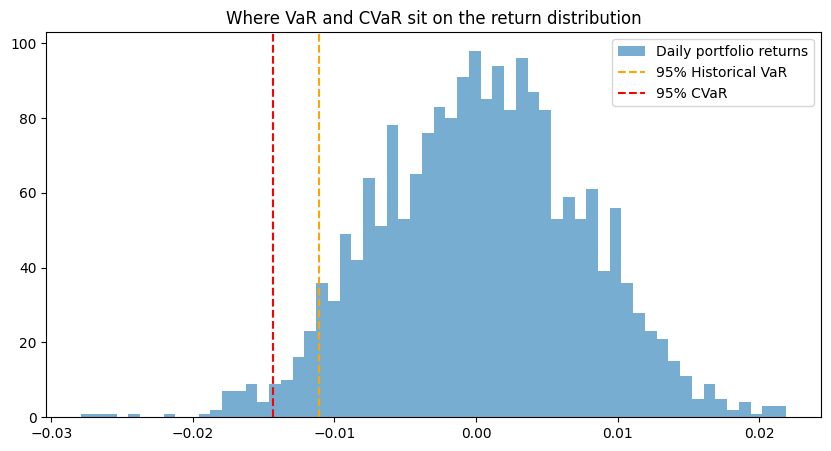

In [5]:
fig, ax = plt.subplots()
ax.hist(port_returns, bins=60, alpha=0.6, label="Daily portfolio returns")
ax.axvline(-var_table.loc[0.95, "historical_var"], color="orange", linestyle="--", label="95% Historical VaR")
ax.axvline(-var_table.loc[0.95, "cvar"], color="red", linestyle="--", label="95% CVaR")
ax.legend()
ax.set_title("Where VaR and CVaR sit on the return distribution")
plt.show()

## Takeaways

- Both VaR methods are approximations of a threshold, not a worst-case bound — CVaR is more informative about *how bad* the tail actually is.
- Continue to **07 — Monte Carlo Simulation** for a third, resampling-based view of the same risk.